`Figura 4`          Heatmap

`Desiciones:`

-Se promedia la frecuencia por secuencia, no los conteos brutos. Así una secuencia larga no pesa más que una corta.

-$ifNull(..., 0): como solo guardaste los k-mers presentes, un 2-mer ausente cuenta como frecuencia 0, no como dato faltante.

se imprimen las secuencias por orden y el control (debe sumar 1)

In [2]:
import sys
sys.path.append("..")            # el notebook está en notebooks/

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from pymongo import MongoClient

from src.figuras_c import frecuencias_2mers_por_orden, DINUC

db = MongoClient("mongodb://localhost:27017/")["panteon_prueba"]

df = frecuencias_2mers_por_orden(db)
mat = df[DINUC]
print(df["n"])
print(df[DINUC].sum(axis=1).round(3).unique())   # debe mostrar [1.]

te_orden
CRYPTON          112
DIRS            2933
HELITRON        5075
LINE           68382
LTR           119368
MAVERICK          58
MITE            3456
PLE              344
RETROPOSON       113
SINE            3634
TIR            36471
Name: n, dtype: int64
[1.]


Construccion del HeatMap

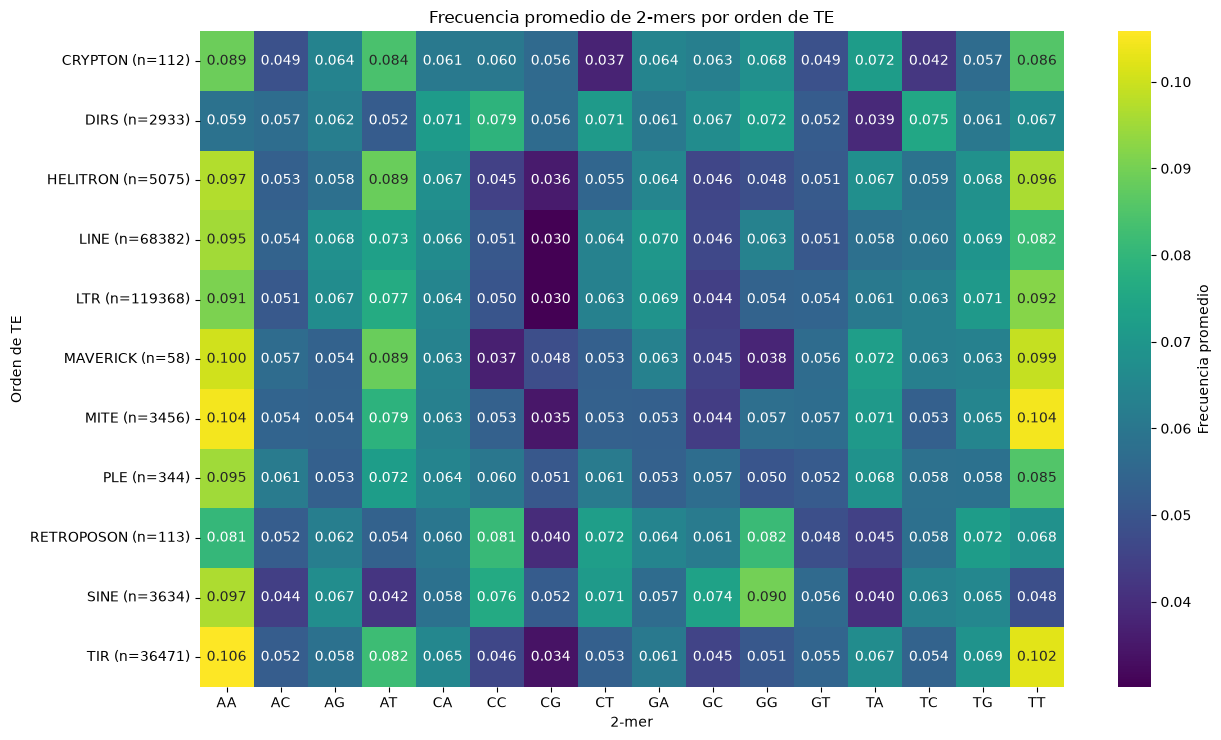

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

mat = df[DINUC]
etiquetas = [f"{o} (n={n})" for o, n in df["n"].items()]

fig, ax = plt.subplots(figsize=(13, 0.5 * len(mat) + 2))
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis",
            yticklabels=etiquetas, cbar_kws={"label": "Frecuencia promedio"}, ax=ax)
ax.set_title("Frecuencia promedio de 2-mers por orden de TE")
ax.set_xlabel("2-mer"); ax.set_ylabel("Orden de TE")
plt.tight_layout()
Path("../figuras").mkdir(exist_ok=True)
plt.savefig("../figuras/heatmap_2mers_orden.png", dpi=200)
plt.show()

``Agrupacion de ordenes parecidos``


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


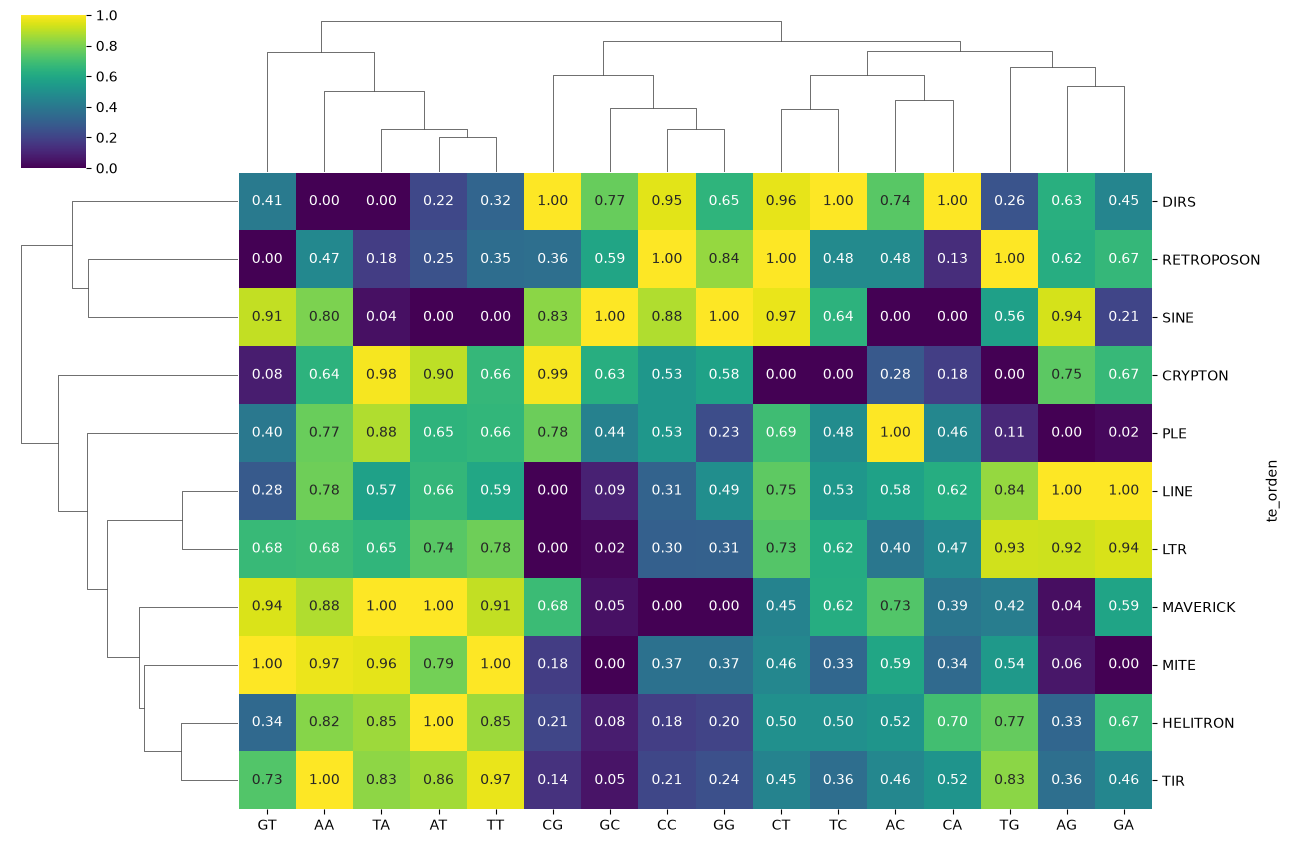

In [3]:
%pip install scipy
g = sns.clustermap(mat, cmap="viridis", annot=True, fmt=".2f",
                   standard_scale=1,          # normaliza cada 2-mer para ver diferencias relativas
                   figsize=(13, 0.5 * len(mat) + 3))
g.savefig("../figuras/clustermap_2mers_orden.png", dpi=200)

``Media numerica de similutud``

In [5]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

dist = pd.DataFrame(squareform(pdist(mat)), index=mat.index, columns=mat.index)
triu = dist.where(np.triu(np.ones(dist.shape, bool), k=1))   # k=1 excluye la diagonal
pares = triu.stack().dropna().sort_values()

print("Más parecidos:\n", pares.head(5).round(4))
print("Más distintos:\n", pares.tail(5).round(4))

Más parecidos:
 te_orden  te_orden
HELITRON  TIR         0.0151
MITE      TIR         0.0159
LINE      LTR         0.0168
HELITRON  MAVERICK    0.0222
          LTR         0.0235
dtype: float64
Más distintos:
 te_orden  te_orden
MITE      SINE        0.0947
DIRS      MAVERICK    0.0969
SINE      TIR         0.0975
HELITRON  SINE        0.0977
MAVERICK  SINE        0.1076
dtype: float64


`¿Que nos dicen las tablas y que podemos analizar de las figuras?`

``Qué dicen``

SINE aparece en 4 de los 5 pares más distintos, siempre frente a los órdenes del bloque AA/TT alto (MAVERICK, HELITRON, TIR, MITE). Es el orden más atípico de la base, y eso coincide con lo que se ve en el heatmap: TT=0,048 y AT=0,042 en SINE frente a 0,082 a 0,104 en esos órdenes. La distancia más grande (0,1076) es unas 7 veces la más pequeña (0,0151).

DIRS-MAVERICK es el único par de los más distintos que no incluye a SINE. Es coherente con lo anterior: DIRS comparte con SINE un perfil más rico en CC/GG y pobre en AT, y MAVERICK está en el extremo opuesto (AA=0,100, TT=0,099).

``Interpretación final``

Las distancias euclidianas entre perfiles de 2-mers confirman dos extremos. Los órdenes más parecidos son HELITRON-TIR (0,0151), MITE-TIR (0,0159) y LINE-LTR (0,0168). Los más distintos son MAVERICK-SINE (0,1076), HELITRON-SINE (0,0977) y SINE-TIR (0,0975). SINE interviene en 4 de los 5 pares más alejados, por lo que es el orden con el perfil más singular: TT y AT bajos (0,048 y 0,042) y GG y CC altos (0,090 y 0,076). El otro par extremo, DIRS-MAVERICK (0,0969), refleja la misma oposición entre perfiles ricos en G+C y perfiles dominados por AA/TT. La separación entre extremos es unas 7 veces la distancia entre los órdenes más parecidos, así que los perfiles de dinucleótidos sí distinguen unos órdenes de otros.